<a href="https://colab.research.google.com/github/samafarouk/Mini-Quant-Lab-Project-Series/blob/main/Valuation%20DCF%20Model.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [3]:

# Our DCF model assumptions

current_fcff = 100       # EGP millions
growth_rate = 0.08       # 8%
wacc = 0.12              # 12%
terminal_growth = 0.03   # 3%
forecast_years = 5

print("DCF Model Assumptions")
print("Current FCFF:", current_fcff, "million EGP")
print("Annual Growth:", growth_rate * 100, "%")
print("WACC:", wacc * 100, "%")
print("Terminal Growth:", terminal_growth * 100, "%")

fcff_forecast = []

for year in range(1, forecast_years + 1):
    fcff = current_fcff * (1 + growth_rate) ** year
    fcff_forecast.append(fcff)

print("Projected Free Cash Flows (EGP millions)")

for year, fcff in enumerate(fcff_forecast, start=1):
    print(f"Year {year}: {fcff:.2f}")


discounted_fcff = []

for year, fcff in enumerate(fcff_forecast, start=1):
    present_value = fcff / (1 + wacc) ** year
    discounted_fcff.append(present_value)

pv_of_cash_flows = sum(discounted_fcff)

print("Present Value of Forecast Cash Flows:",
      round(pv_of_cash_flows, 2), "million EGP")


terminal_value = (
    fcff_forecast[-1] * (1 + terminal_growth)
    / (wacc - terminal_growth)
)

pv_terminal_value = (
    terminal_value / (1 + wacc) ** forecast_years
)

enterprise_value = pv_of_cash_flows + pv_terminal_value

print("Terminal Value:", round(terminal_value, 2))
print("Present Value of Terminal Value:",
      round(pv_terminal_value, 2))
print("Enterprise Value:", round(enterprise_value, 2),
      "million EGP")


# Additional assumptions (illustrative)
net_debt = 250             # EGP millions
shares_outstanding = 100   # millions of shares

# Calculate equity value
equity_value = enterprise_value - net_debt

# Calculate intrinsic value per share
intrinsic_value_per_share = (
    equity_value / shares_outstanding
)

print("Equity Value:",
      round(equity_value, 2), "million EGP")

print("Intrinsic Value per Share:",
      round(intrinsic_value_per_share, 2), "EGP")



DCF Model Assumptions
Current FCFF: 100 million EGP
Annual Growth: 8.0 %
WACC: 12.0 %
Terminal Growth: 3.0 %
Projected Free Cash Flows (EGP millions)
Year 1: 108.00
Year 2: 116.64
Year 3: 125.97
Year 4: 136.05
Year 5: 146.93
Present Value of Forecast Cash Flows: 448.91 million EGP
Terminal Value: 1681.56
Present Value of Terminal Value: 954.16
Enterprise Value: 1403.08 million EGP
Equity Value: 1153.08 million EGP
Intrinsic Value per Share: 11.53 EGP


In [4]:

def calculate_dcf(wacc_value):
    pv_cash_flows = sum(
        fcff / (1 + wacc_value) ** year
        for year, fcff in enumerate(
            fcff_forecast, start=1
        )
    )

    terminal_value = (
        fcff_forecast[-1] * (1 + terminal_growth)
        / (wacc_value - terminal_growth)
    )

    pv_terminal = (
        terminal_value / (1 + wacc_value)
        ** forecast_years
    )

    return pv_cash_flows + pv_terminal


for rate in [0.10, 0.12, 0.15, 0.18]:
    value = calculate_dcf(rate)
    print(f"WACC: {rate:.0%} | "
          f"Enterprise Value: EGP {value:.2f}M")


WACC: 10% | Enterprise Value: EGP 1815.82M
WACC: 12% | Enterprise Value: EGP 1403.08M
WACC: 15% | Enterprise Value: EGP 1042.80M
WACC: 18% | Enterprise Value: EGP 827.38M


In [5]:

print(calculate_dcf(0.12))
print(calculate_dcf(0.15))
print(calculate_dcf(0.18))


1403.0770056747187
1042.8017281241855
827.3789746793882


In [6]:

import pandas as pd

wacc_rates = [0.10, 0.12, 0.14, 0.16]
growth_rates = [0.02, 0.03, 0.04, 0.05]

sensitivity = pd.DataFrame(
    index=[f"{rate:.0%}" for rate in wacc_rates],
    columns=[f"{rate:.0%}" for rate in growth_rates],
    dtype=float
)

for wacc_rate in wacc_rates:
    for growth_rate in growth_rates:
        pv_cash_flows = sum(
            fcff / (1 + wacc_rate) ** year
            for year, fcff in enumerate(
                fcff_forecast, start=1
            )
        )

        terminal_value = (
            fcff_forecast[-1] * (1 + growth_rate)
            / (wacc_rate - growth_rate)
        )

        pv_terminal = (
            terminal_value
            / (1 + wacc_rate) ** forecast_years
        )

        sensitivity.loc[
            f"{wacc_rate:.0%}",
            f"{growth_rate:.0%}"
        ] = pv_cash_flows + pv_terminal

print("Enterprise Value Sensitivity (EGP millions)")
print(sensitivity.round(2))


Enterprise Value Sensitivity (EGP millions)
          2%       3%       4%       5%
10%  1636.61  1815.82  2054.76  2389.29
12%  1299.32  1403.08  1532.77  1699.52
14%  1075.03  1140.94  1220.03  1316.69
16%   915.27   959.86  1011.88  1073.35


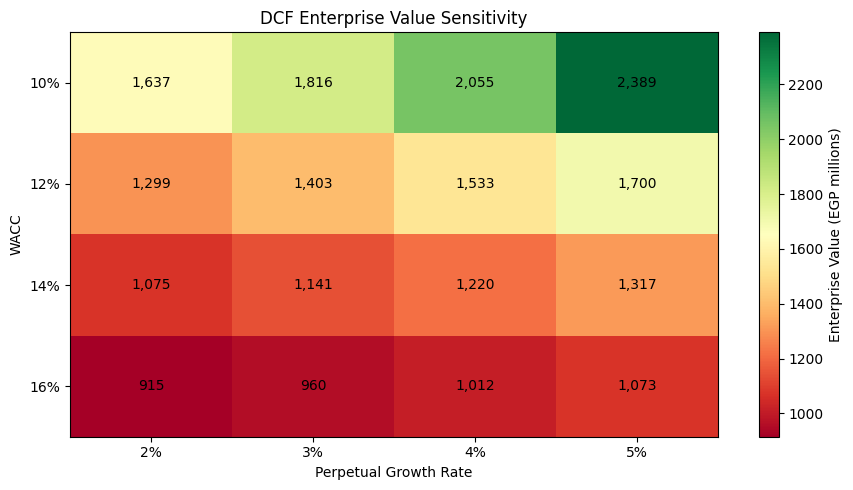

In [7]:

import matplotlib.pyplot as plt

# Create the heatmap
fig, ax = plt.subplots(figsize=(9, 5))

image = ax.imshow(
    sensitivity.astype(float).values,
    cmap="RdYlGn",
    aspect="auto"
)

# Add row and column labels
ax.set_xticks(range(len(sensitivity.columns)))
ax.set_xticklabels(sensitivity.columns)

ax.set_yticks(range(len(sensitivity.index)))
ax.set_yticklabels(sensitivity.index)

ax.set_xlabel("Perpetual Growth Rate")
ax.set_ylabel("WACC")
ax.set_title("DCF Enterprise Value Sensitivity")

# Display the valuation inside each cell
for i in range(len(sensitivity.index)):
    for j in range(len(sensitivity.columns)):
        value = sensitivity.iloc[i, j]
        ax.text(
            j, i, f"{value:,.0f}",
            ha="center",
            va="center",
            color="black"
        )

fig.colorbar(image, ax=ax, label="Enterprise Value (EGP millions)")
plt.tight_layout()
plt.show()


In [15]:


def calculate_dcf(
    current_fcff,
    growth_rate,
    wacc,
    terminal_growth,
    forecast_years,
    net_debt,
    shares_outstanding
):
    # 1. Validate the assumptions
    if current_fcff <= 0:
        raise ValueError("Current FCFF must be positive.")

    if growth_rate <= -1:
        raise ValueError("FCFF growth must be greater than -100%.")

    if wacc <= 0:
        raise ValueError("WACC must be positive.")

    if terminal_growth < 0:
        raise ValueError("Terminal growth cannot be negative.")

    if wacc <= terminal_growth:
        raise ValueError(
            "WACC must be greater than terminal growth."
        )

    if not isinstance(forecast_years, int) or forecast_years < 1:
        raise ValueError("Forecast years must be a positive integer.")

    if shares_outstanding <= 0:
        raise ValueError("Shares outstanding must be positive.")

    # 2. Forecast FCFF for each year
    years = list(range(1, forecast_years + 1))

    fcff_forecast = [
        current_fcff * (1 + growth_rate) ** year
        for year in years
    ]

    # 3. Discount each forecast cash flow to today
    discounted_fcff = [
        cash_flow / (1 + wacc) ** year
        for year, cash_flow in zip(years, fcff_forecast)
    ]

    pv_cash_flows = sum(discounted_fcff)

    # 4. Calculate terminal value and discount it
    terminal_value = (
        fcff_forecast[-1] * (1 + terminal_growth)
        / (wacc - terminal_growth)
    )

    pv_terminal = (
        terminal_value / (1 + wacc) ** forecast_years
    )

    # 5. Bridge enterprise value to equity value
    enterprise_value = pv_cash_flows + pv_terminal
    equity_value = enterprise_value - net_debt
    value_per_share = equity_value / shares_outstanding

    return {
        "Enterprise Value": enterprise_value,
        "Equity Value": equity_value,
        "Value per Share": value_per_share,
        "PV of Forecast Cash Flows": pv_cash_flows,
        "Terminal Value": terminal_value,
        "PV of Terminal Value": pv_terminal,
        "FCFF Forecast": fcff_forecast,
        "Years": years
    }

In [11]:

import ipywidgets as widgets
from IPython.display import display, clear_output
import pandas as pd
import matplotlib.pyplot as plt

# Create the assumption controls
fcff_slider = widgets.FloatSlider(
    value=100, min=50, max=200, step=5,
    description="Current FCFF",
    style={"description_width": "initial"}
)

growth_slider = widgets.FloatSlider(
    value=0.08, min=0, max=0.20, step=0.01,
    description="FCFF Growth",
    readout_format=".0%",
    style={"description_width": "initial"}
)

wacc_slider = widgets.FloatSlider(
    value=0.12, min=0.04, max=0.25, step=0.01,
    description="WACC",
    readout_format=".0%",
    style={"description_width": "initial"}
)

terminal_slider = widgets.FloatSlider(
    value=0.03, min=0, max=0.08, step=0.01,
    description="Terminal Growth",
    readout_format=".0%",
    style={"description_width": "initial"}
)

years_slider = widgets.IntSlider(
    value=5, min=3, max=10, step=1,
    description="Forecast Years",
    style={"description_width": "initial"}
)

debt_slider = widgets.FloatSlider(
    value=250, min=0, max=500, step=10,
    description="Net Debt (EGP M)",
    style={"description_width": "initial"}
)

shares_slider = widgets.FloatSlider(
    value=100, min=10, max=200, step=10,
    description="Shares (millions)",
    style={"description_width": "initial"}
)

print("Your DCF assumptions are ready!")


Your DCF assumptions are ready!


In [16]:


def update_dashboard(
    current_fcff,
    growth_rate,
    wacc,
    terminal_growth,
    forecast_years,
    net_debt,
    shares_outstanding
):
    clear_output(wait=True)

    # Calculate the base case
    try:
        base = calculate_dcf(
            current_fcff, growth_rate, wacc,
            terminal_growth, forecast_years,
            net_debt, shares_outstanding
        )
    except (ValueError, OverflowError) as error:
        print("Please check your assumptions:", error)
        return

    # Create downside and upside assumptions
    downside_growth = growth_rate - 0.02
    downside_wacc = wacc + 0.02
    downside_terminal = max(0, terminal_growth - 0.01)

    upside_growth = growth_rate + 0.02
    upside_wacc = max(wacc - 0.02, terminal_growth + 0.02)
    upside_terminal = min(
        terminal_growth + 0.01,
        upside_wacc - 0.01
    )

    scenarios = {
        "Downside": (
            downside_growth, downside_wacc, downside_terminal
        ),
        "Base": (growth_rate, wacc, terminal_growth),
        "Upside": (
            upside_growth, upside_wacc, upside_terminal
        )
    }

    scenario_results = {}

    for name, assumptions in scenarios.items():
        g, r, tg = assumptions

        scenario_results[name] = calculate_dcf(
            current_fcff, g, r, tg,
            forecast_years, net_debt, shares_outstanding
        )

    # Display the key valuation outputs
    print("DCF VALUATION DASHBOARD")
    print("=" * 45)
    print(f"Enterprise Value: EGP {base['Enterprise Value']:,.2f}M")
    print(f"Equity Value: EGP {base['Equity Value']:,.2f}M")
    print(f"Intrinsic Value per Share: EGP {base['Value per Share']:,.2f}")
    print(f"PV of Forecast Cash Flows: EGP {base['PV of Forecast Cash Flows']:,.2f}M")
    print(f"PV of Terminal Value: EGP {base['PV of Terminal Value']:,.2f}M")

    # Compare downside, base, and upside scenarios
    scenario_rows = []

    for name, assumptions in scenarios.items():
        g, r, tg = assumptions
        result = scenario_results[name]

        scenario_rows.append({
            "Scenario": name,
            "FCFF Growth": g,
            "WACC": r,
            "Terminal Growth": tg,
            "Enterprise Value (EGP M)": result["Enterprise Value"],
            "Equity Value (EGP M)": result["Equity Value"],
            "Value per Share (EGP)": result["Value per Share"]
        })

    scenario_table = pd.DataFrame(scenario_rows)

    print("\nSCENARIO ANALYSIS")
    display(
        scenario_table.style.format({
            "FCFF Growth": "{:.1%}",
            "WACC": "{:.1%}",
            "Terminal Growth": "{:.1%}",
            "Enterprise Value (EGP M)": "{:,.2f}",
            "Equity Value (EGP M)": "{:,.2f}",
            "Value per Share (EGP)": "{:,.2f}"
        })
    )

    # Build a sensitivity table around the current assumptions
    wacc_rates = sorted(set([
        max(wacc - 0.02, 0.001),
        wacc,
        wacc + 0.02
    ]))

    growth_rates = sorted(set([
        max(0, terminal_growth - 0.01),
        terminal_growth,
        terminal_growth + 0.01
    ]))

    sensitivity = pd.DataFrame(
        index=[f"{r:.1%}" for r in wacc_rates],
        columns=[f"{g:.1%}" for g in growth_rates],
        dtype=float
    )

    for r in wacc_rates:
        for g in growth_rates:
            if r <= g:
                sensitivity.loc[f"{r:.1%}", f"{g:.1%}"] = float("nan")
            else:
                result = calculate_dcf(
                    current_fcff, growth_rate, r, g,
                    forecast_years, net_debt, shares_outstanding
                )
                sensitivity.loc[f"{r:.1%}", f"{g:.1%}"] = (
                    result["Enterprise Value"]
                )

    print("\nENTERPRISE VALUE SENSITIVITY (EGP MILLIONS)")
    print("Rows = WACC | Columns = Terminal Growth")

    display(
        sensitivity.style
        .format("{:,.2f}", na_rep="N/A")
        .background_gradient(cmap="RdYlGn", axis=None)
    )

    # Show the base-case cash-flow forecast
    forecast_table = pd.DataFrame({
        "Year": base["Years"],
        "Projected FCFF (EGP M)": base["FCFF Forecast"]
    })

    print("\nBASE-CASE CASH FLOW FORECAST")
    display(forecast_table.round(2))

    plt.figure(figsize=(8, 4))
    plt.bar(base["Years"], base["FCFF Forecast"])
    plt.title("Base-Case Projected Free Cash Flow")
    plt.xlabel("Forecast Year")
    plt.ylabel("FCFF (EGP millions)")
    plt.xticks(base["Years"])
    plt.tight_layout()
    plt.show()


controls = {
    "current_fcff": fcff_slider,
    "growth_rate": growth_slider,
    "wacc": wacc_slider,
    "terminal_growth": terminal_slider,
    "forecast_years": years_slider,
    "net_debt": debt_slider,
    "shares_outstanding": shares_slider
}

dashboard = widgets.interactive_output(
    update_dashboard, controls
)

inputs = widgets.VBox([
    fcff_slider,
    growth_slider,
    wacc_slider,
    terminal_slider,
    years_slider,
    debt_slider,
    shares_slider
])

display(inputs, dashboard)



Output()

In [18]:

import io
import pandas as pd
import matplotlib.pyplot as plt
import ipywidgets as widgets

from IPython.display import display, clear_output

# ==========================================
# 1. CREATE THE FINANCIAL INPUT FORM
# ==========================================

company_input = widgets.Text(
    value="Example Company",
    description="Company:",
    style={"description_width": "initial"}
)

fcff_input = widgets.FloatText(
    value=100, description="Current FCFF (EGP M):",
    style={"description_width": "initial"}
)

growth_input = widgets.FloatText(
    value=8, description="FCFF Growth (%):",
    style={"description_width": "initial"}
)

wacc_input = widgets.FloatText(
    value=12, description="WACC (%):",
    style={"description_width": "initial"}
)

terminal_input = widgets.FloatText(
    value=3, description="Terminal Growth (%):",
    style={"description_width": "initial"}
)

years_input = widgets.BoundedIntText(
    value=5, min=1, max=20,
    description="Forecast Years:",
    style={"description_width": "initial"}
)

debt_input = widgets.FloatText(
    value=250, description="Net Debt (EGP M):",
    style={"description_width": "initial"}
)

shares_input = widgets.FloatText(
    value=100, description="Shares Outstanding (M):",
    style={"description_width": "initial"}
)

# ==========================================
# 2. CREATE FILE UPLOAD AND OUTPUT AREAS
# ==========================================

file_upload = widgets.FileUpload(
    accept=".csv,.xlsx",
    multiple=False,
    description="Upload CSV / Excel"
)

dashboard_output = widgets.Output()
upload_status = widgets.Output()

# ==========================================
# 3. BUILD THE VALUATION DASHBOARD
# ==========================================

def update_dashboard(change=None):

    with dashboard_output:
        clear_output(wait=True)

        company = company_input.value.strip()

        if not company:
            print("Please enter a company name.")
            return

        try:
            current_fcff = fcff_input.value
            growth = growth_input.value / 100
            wacc = wacc_input.value / 100
            terminal_growth = terminal_input.value / 100
            years = years_input.value
            net_debt = debt_input.value
            shares = shares_input.value

            # Base-case valuation
            base = calculate_dcf(
                current_fcff, growth, wacc,
                terminal_growth, years,
                net_debt, shares
            )

            # Downside and upside assumptions
            downside = (
                growth - 0.02,
                wacc + 0.02,
                max(0, terminal_growth - 0.01)
            )

            upside_wacc = max(
                wacc - 0.02, terminal_growth + 0.02
            )

            upside_terminal = min(
                terminal_growth + 0.01,
                upside_wacc - 0.01
            )

            upside = (
                growth + 0.02,
                upside_wacc,
                upside_terminal
            )

            scenario_inputs = {
                "Downside": downside,
                "Base": (growth, wacc, terminal_growth),
                "Upside": upside
            }

            scenario_rows = []

            for name, assumptions in scenario_inputs.items():

                g, r, tg = assumptions

                result = calculate_dcf(
                    current_fcff, g, r, tg,
                    years, net_debt, shares
                )

                scenario_rows.append({
                    "Scenario": name,
                    "FCFF Growth": g,
                    "WACC": r,
                    "Terminal Growth": tg,
                    "Enterprise Value (EGP M)": result[
                        "Enterprise Value"
                    ],
                    "Equity Value (EGP M)": result[
                        "Equity Value"
                    ],
                    "Value per Share (EGP)": result[
                        "Value per Share"
                    ]
                })

            scenarios = pd.DataFrame(scenario_rows)

            # Sensitivity table: enterprise value
            wacc_rates = sorted(set([
                max(0.001, wacc - 0.02),
                wacc,
                wacc + 0.02
            ]))

            growth_rates = sorted(set([
                max(0, terminal_growth - 0.01),
                terminal_growth,
                terminal_growth + 0.01
            ]))

            sensitivity = pd.DataFrame(
                index=[f"{r:.1%}" for r in wacc_rates],
                columns=[f"{g:.1%}" for g in growth_rates],
                dtype=float
            )

            for r in wacc_rates:
                for g in growth_rates:

                    row = f"{r:.1%}"
                    col = f"{g:.1%}"

                    if r <= g:
                        sensitivity.loc[row, col] = float("nan")
                    else:
                        result = calculate_dcf(
                            current_fcff, growth, r, g,
                            years, net_debt, shares
                        )

                        sensitivity.loc[row, col] = result[
                            "Enterprise Value"
                        ]

            # Display key valuation results
            print(f"DCF VALUATION REPORT: {company.upper()}")
            print("=" * 50)

            print(
                f"Enterprise Value: EGP "
                f"{base['Enterprise Value']:,.2f}M"
            )
            print(
                f"Equity Value: EGP "
                f"{base['Equity Value']:,.2f}M"
            )
            print(
                f"Intrinsic Value per Share: EGP "
                f"{base['Value per Share']:,.2f}"
            )
            print(
                f"PV of Forecast Cash Flows: EGP "
                f"{base['PV of Forecast Cash Flows']:,.2f}M"
            )
            print(
                f"PV of Terminal Value: EGP "
                f"{base['PV of Terminal Value']:,.2f}M"
            )

            print("\nSCENARIO ANALYSIS")

            display(scenarios.style.format({
                "FCFF Growth": "{:.1%}",
                "WACC": "{:.1%}",
                "Terminal Growth": "{:.1%}",
                "Enterprise Value (EGP M)": "{:,.2f}",
                "Equity Value (EGP M)": "{:,.2f}",
                "Value per Share (EGP)": "{:,.2f}"
            }))

            print("\nENTERPRISE VALUE SENSITIVITY (EGP M)")
            print("Rows: WACC | Columns: Terminal Growth")

            display(
                sensitivity.style
                .format("{:,.2f}", na_rep="N/A")
                .background_gradient(cmap="RdYlGn", axis=None)
            )

            # Forecast table and chart
            forecast = pd.DataFrame({
                "Year": base["Years"],
                "FCFF (EGP M)": base["FCFF Forecast"]
            })

            print("\nPROJECTED FREE CASH FLOWS")
            display(forecast.round(2))

            plt.figure(figsize=(8, 4))
            plt.bar(base["Years"], base["FCFF Forecast"])
            plt.title(f"{company}: Projected Free Cash Flow")
            plt.xlabel("Forecast Year")
            plt.ylabel("FCFF (EGP millions)")
            plt.xticks(base["Years"])
            plt.tight_layout()
            plt.show()

        except (ValueError, OverflowError) as error:
            print("Cannot calculate valuation:", error)


# ==========================================
# 4. LOAD CSV OR EXCEL FINANCIAL INPUTS
# ==========================================

def load_uploaded_file(change):

    if not file_upload.value:
        return

    with upload_status:
        clear_output(wait=True)

        try:
            uploaded = file_upload.value

            # Support different ipywidgets versions
            if isinstance(uploaded, dict):
                metadata = next(iter(uploaded.values()))
                filename = metadata.get("metadata", {}).get(
                    "name", "uploaded_file"
                )
                content = metadata["content"]

            else:
                metadata = uploaded[0]
                filename = metadata.get("name", "uploaded_file")
                content = metadata["content"]

            content = bytes(content)

            # Read the uploaded file
            if filename.lower().endswith(".csv"):
                data = pd.read_csv(io.BytesIO(content))
            elif filename.lower().endswith(".xlsx"):
                data = pd.read_excel(io.BytesIO(content))
            else:
                print("Please upload a CSV or XLSX file.")
                return

            # Normalize column names
            data.columns = [
                str(column).strip().lower()
                for column in data.columns
            ]

            if data.empty:
                print("The uploaded file contains no data.")
                return

            row = data.iloc[0]

            required_columns = [
                "current_fcff",
                "growth_rate",
                "wacc",
                "terminal_growth",
                "forecast_years",
                "net_debt",
                "shares_outstanding"
            ]

            missing = [
                column for column in required_columns
                if column not in data.columns
            ]

            if missing:
                print("Missing required columns:", ", ".join(missing))
                print("See the input template below.")
                return

            # Percentages in the file are entered as whole numbers:
            # 8 means 8%, not 0.08.
            company_input.value = str(
                row.get("company", "Uploaded Company")
            )

            fcff_input.value = float(row["current_fcff"])
            growth_input.value = float(row["growth_rate"])
            wacc_input.value = float(row["wacc"])
            terminal_input.value = float(row["terminal_growth"])
            years_input.value = int(row["forecast_years"])
            debt_input.value = float(row["net_debt"])
            shares_input.value = float(row["shares_outstanding"])

            print(f"Successfully loaded: {filename}")
            print("The valuation dashboard has been updated.")

        except Exception as error:
            print("File could not be loaded:", error)


# ==========================================
# 5. CONNECT INPUTS TO THE DASHBOARD
# ==========================================

input_fields = [
    company_input, fcff_input, growth_input,
    wacc_input, terminal_input, years_input,
    debt_input, shares_input
]

for field in input_fields:
    field.observe(update_dashboard, names="value")

file_upload.observe(load_uploaded_file, names="value")

# Display the complete application
display(widgets.HTML("<h2>DCF Valuation Workbench</h2>"))
display(widgets.HTML(
    "<b>Option A:</b> Enter assumptions manually."
))
display(widgets.VBox(input_fields))

display(widgets.HTML(
    "<b>Option B:</b> Upload a CSV or Excel file."
))
display(file_upload, upload_status)

display(widgets.HTML("<hr><h3>Valuation Results</h3>"))
display(dashboard_output)

update_dashboard()


HTML(value='<h2>DCF Valuation Workbench</h2>')

HTML(value='<b>Option A:</b> Enter assumptions manually.')

HTML(value='<b>Option B:</b> Upload a CSV or Excel file.')

FileUpload(value={}, accept='.csv,.xlsx', description='Upload CSV / Excel')

Output()

HTML(value='<hr><h3>Valuation Results</h3>')

Output()

In [20]:

import pandas as pd
from google.colab import files

template = pd.DataFrame([{
    "company": "Example Company",
    "current_fcff": 100,
    "growth_rate": 8,
    "wacc": 12,
    "terminal_growth": 3,
    "forecast_years": 5,
    "net_debt": 250,
    "shares_outstanding": 100
}])

template.to_csv("dcf_input_template.csv", index=False)

files.download("dcf_input_template.csv")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [21]:

import pandas as pd

# Fictional historical financial statements
financial_data = pd.DataFrame({
    "Year": [2023, 2024, 2025],
    "EBIT": [350, 420, 500],
    "Tax_Rate": [22, 22, 22],
    "D&A": [60, 70, 80],
    "CapEx": [90, 100, 120],
    "Receivables": [100, 120, 150],
    "Inventory": [140, 170, 200],
    "Payables": [80, 95, 110]
})

# Export to Excel
financial_data.to_excel(
    "financial_statements_template.xlsx",
    index=False
)

print("Excel template created!")
display(financial_data)


Excel template created!


,Year,EBIT,Tax_Rate,D&A,CapEx,Receivables,Inventory,Payables
0,2023,350,22,60,90,100,140,80
1,2024,420,22,70,100,120,170,95
2,2025,500,22,80,120,150,200,110


In [22]:

from google.colab import files

files.download("financial_statements_template.xlsx")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [23]:

def calculate_fcff(financial_data):

    # Work on a copy so we don't overwrite the original data
    df = financial_data.copy()

    # Make sure the years are in chronological order
    df = df.sort_values("Year").reset_index(drop=True)

    # Calculate after-tax operating profit
    df["NOPAT"] = df["EBIT"] * (
        1 - df["Tax_Rate"] / 100
    )

    # Calculate operating net working capital
    df["NWC"] = (
        df["Receivables"]
        + df["Inventory"]
        - df["Payables"]
    )

    # Calculate the change in working capital from the prior year
    df["Change_NWC"] = df["NWC"].diff()

    # Calculate FCFF
    df["FCFF"] = (
        df["NOPAT"]
        + df["D&A"]
        - df["CapEx"]
        - df["Change_NWC"]
    )

    return df


# Run the function on our sample financial statements
fcff_results = calculate_fcff(financial_data)

display(
    fcff_results[
        ["Year", "EBIT", "NOPAT", "NWC",
         "Change_NWC", "D&A", "CapEx", "FCFF"]
    ].round(2)
)


,Year,EBIT,NOPAT,NWC,Change_NWC,D&A,CapEx,FCFF
0,2023,350,273.0,160,NaN,60,90,NaN
1,2024,420,327.6,195,35.0,70,100,262.6
2,2025,500,390.0,240,45.0,80,120,305.0


In [27]:

from google.colab import files
import pandas as pd
import io

uploaded_files = files.upload()

# Read the first uploaded Excel workbook
filename = next(iter(uploaded_files))

financial_data = pd.read_excel(
    io.BytesIO(uploaded_files[filename])
)

# Clean up column headings
financial_data.columns = [
    str(column).strip() for column in financial_data.columns
]

required_columns = [
    "Year", "EBIT", "Tax_Rate", "D&A", "CapEx",
    "Receivables", "Inventory", "Payables"
]

missing_columns = [
    column for column in required_columns
    if column not in financial_data.columns
]

if missing_columns:
    raise ValueError(
        f"Missing required columns: {missing_columns}"
    )

print(f"Successfully loaded: {filename}")
display(financial_data.head())


KeyboardInterrupt: 

In [25]:

fcff_results = calculate_fcff(financial_data)

# The first year has no prior year for calculating change in NWC.
# Exclude rows where FCFF cannot be calculated.
valid_fcff = fcff_results.dropna(subset=["FCFF"]).copy()

if valid_fcff.empty:
    raise ValueError(
        "Not enough consecutive annual data to calculate FCFF."
    )

latest_row = valid_fcff.iloc[-1]

current_fcff = float(latest_row["FCFF"])

print("Latest financial year:", int(latest_row["Year"]))
print("Calculated current FCFF:", round(current_fcff, 2),
      "million EGP")


Latest financial year: 2025
Calculated current FCFF: 305.0 million EGP


In [26]:

# Forecasting assumptions (illustrative)
forecast_growth = 0.08
wacc = 0.12
terminal_growth = 0.03
forecast_years = 5

# Capital structure assumptions (illustrative)
net_debt = 250
shares_outstanding = 100

# Run the existing DCF function
valuation = calculate_dcf(
    current_fcff,
    forecast_growth,
    wacc,
    terminal_growth,
    forecast_years,
    net_debt,
    shares_outstanding
)

print("DCF VALUATION FROM FINANCIAL STATEMENTS")
print("=" * 45)
print(
    f"Enterprise Value: EGP "
    f"{valuation['Enterprise Value']:,.2f} million"
)
print(
    f"Equity Value: EGP "
    f"{valuation['Equity Value']:,.2f} million"
)
print(
    f"Intrinsic Value per Share: EGP "
    f"{valuation['Value per Share']:,.2f}"
)


DCF VALUATION FROM FINANCIAL STATEMENTS
Enterprise Value: EGP 4,279.38 million
Equity Value: EGP 4,029.38 million
Intrinsic Value per Share: EGP 40.29


In [ ]:

# ==========================================================
# DCF VALUATION WORKBENCH
# Inputs + Financial Statement Import + Dashboard + Export
# ==========================================================

import io
import pandas as pd
import matplotlib.pyplot as plt
import ipywidgets as widgets

from IPython.display import display, clear_output, HTML
from google.colab import files

# ----------------------------------------------------------
# 1. STORE THE APPLICATION'S DATA
# ----------------------------------------------------------

app_data = {
    "financial_statements": None,
    "fcff_history": None,
    "latest_fcff": None,
    "latest_year": None,
    "results": None,
    "scenarios": None,
    "sensitivity": None,
    "forecast": None,
    "company": "Example Company"
}

# ----------------------------------------------------------
# 2. CREATE THE INPUT CONTROLS
# ----------------------------------------------------------

company = widgets.Text(
    value="Example Company",
    description="Company:",
    style={"description_width": "initial"},
    layout=widgets.Layout(width="450px")
)

fcff = widgets.FloatText(
    value=100,
    description="Manual FCFF (EGP M):",
    style={"description_width": "initial"}
)

growth = widgets.FloatText(
    value=8,
    description="FCFF Growth (%):",
    style={"description_width": "initial"}
)

wacc = widgets.FloatText(
    value=12,
    description="WACC (%):",
    style={"description_width": "initial"}
)

terminal_growth = widgets.FloatText(
    value=3,
    description="Terminal Growth (%):",
    style={"description_width": "initial"}
)

forecast_years = widgets.BoundedIntText(
    value=5,
    min=1,
    max=20,
    description="Forecast Years:",
    style={"description_width": "initial"}
)

net_debt = widgets.FloatText(
    value=250,
    description="Net Debt (EGP M):",
    style={"description_width": "initial"}
)

shares = widgets.FloatText(
    value=100,
    description="Shares Outstanding (M):",
    style={"description_width": "initial"}
)

fcff_source = widgets.ToggleButtons(
    options=[
        ("Manual FCFF", "manual"),
        ("Uploaded Statements", "uploaded")
    ],
    value="manual",
    description="FCFF Source:",
    style={"description_width": "initial"}
)

upload = widgets.FileUpload(
    accept=".xlsx,.csv",
    multiple=False,
    description="Upload Statements"
)

calculate_button = widgets.Button(
    description="Calculate Valuation",
    button_style="primary",
    icon="calculator"
)

export_excel_button = widgets.Button(
    description="Export Excel Report",
    icon="file-excel"
)

export_csv_button = widgets.Button(
    description="Export CSV Tables",
    icon="download"
)

status = widgets.Output()
dashboard_output = widgets.Output()
statements_output = widgets.Output()
export_status = widgets.Output()

# ----------------------------------------------------------
# 3. READ UPLOADED FINANCIAL STATEMENTS
# ----------------------------------------------------------

def read_uploaded_file(upload_value):

    if not upload_value:
        raise ValueError("Please upload a financial statements file.")

    # Support multiple ipywidgets versions
    if isinstance(upload_value, dict):
        filename, item = next(iter(upload_value.items()))
        content = item["content"]
    else:
        item = upload_value[0]
        filename = item.get("name", "uploaded_file")
        content = item["content"]

    content = bytes(content)

    if filename.lower().endswith(".csv"):
        data = pd.read_csv(io.BytesIO(content))

    elif filename.lower().endswith(".xlsx"):
        data = pd.read_excel(io.BytesIO(content))

    else:
        raise ValueError("Upload a .xlsx or .csv file.")

    data.columns = [
        str(col).strip() for col in data.columns
    ]

    required = [
        "Year", "EBIT", "Tax_Rate", "D&A", "CapEx",
        "Receivables", "Inventory", "Payables"
    ]

    missing = [
        col for col in required if col not in data.columns
    ]

    if missing:
        raise ValueError(
            "Missing columns: " + ", ".join(missing)
            + ". Use the financial statement template."
        )

    if data.empty:
        raise ValueError("The uploaded file is empty.")

    for col in required:
        data[col] = pd.to_numeric(data[col], errors="raise")

    if data["Year"].duplicated().any():
        raise ValueError("Each financial year must appear once.")

    data = data.sort_values("Year").reset_index(drop=True)

    if data[required].isna().any().any():
        raise ValueError(
            "Required columns contain missing values."
        )

    if not data["Year"].mod(1).eq(0).all():
        raise ValueError("Year must contain whole-number years.")

    if (data["Tax_Rate"] < 0).any() or (
        data["Tax_Rate"] > 100
    ).any():
        raise ValueError("Tax_Rate must be between 0 and 100.")

    for col in ["Receivables", "Inventory", "Payables", "CapEx", "D&A"]:
        if (data[col] < 0).any():
            raise ValueError(
                f"{col} must be entered as a non-negative amount."
            )

    if len(data) < 2:
        raise ValueError(
            "Upload at least two consecutive years to calculate "
            "the change in working capital."
        )

    return data, filename


def handle_upload(change):

    if not upload.value:
        return

    with status:
        clear_output(wait=True)

        try:
            data, filename = read_uploaded_file(upload.value)

            calculated = calculate_fcff(data)

            valid = calculated.dropna(subset=["FCFF"])

            if valid.empty:
                raise ValueError(
                    "No valid FCFF observations were calculated."
                )

            app_data["financial_statements"] = data
            app_data["fcff_history"] = calculated
            app_data["latest_fcff"] = float(valid.iloc[-1]["FCFF"])
            app_data["latest_year"] = int(valid.iloc[-1]["Year"])

            print("Financial statements imported successfully.")
            print("File:", filename)
            print("Latest valid FCFF year:", app_data["latest_year"])
            print(
                "Calculated FCFF: EGP "
                f"{app_data['latest_fcff']:,.2f} million"
            )

            if fcff_source.value == "uploaded":
                print(
                    "Select Calculate Valuation to update the report."
                )

            with statements_output:
                clear_output(wait=True)
                display(calculated.round(2))

        except Exception as error:
            app_data["financial_statements"] = None
            app_data["fcff_history"] = None
            app_data["latest_fcff"] = None
            app_data["latest_year"] = None
            print("Import error:", error)


upload.observe(handle_upload, names="value")

# ----------------------------------------------------------
# 4. CALCULATE THE FULL VALUATION
# ----------------------------------------------------------

def run_valuation(button=None):

    with status:
        clear_output(wait=True)

    with dashboard_output:
        clear_output(wait=True)

        try:
            company_name = company.value.strip()

            if not company_name:
                raise ValueError("Enter a company name.")

            g = growth.value / 100
            r = wacc.value / 100
            tg = terminal_growth.value / 100

            # Select the FCFF source
            if fcff_source.value == "uploaded":

                if app_data["latest_fcff"] is None:
                    raise ValueError(
                        "Upload valid financial statements first."
                    )

                current_fcff = app_data["latest_fcff"]
                source_description = (
                    f"Calculated historical FCFF, "
                    f"{app_data['latest_year']}"
                )

            else:
                current_fcff = fcff.value
                source_description = "Manual FCFF input"

            # Calculate base case
            base = calculate_dcf(
                current_fcff, g, r, tg,
                forecast_years.value,
                net_debt.value,
                shares.value
            )

            # Scenario assumptions
            downside = (
                g - 0.02,
                r + 0.02,
                max(0, tg - 0.01)
            )

            upside_wacc = max(r - 0.02, tg + 0.02)

            upside = (
                g + 0.02,
                upside_wacc,
                min(tg + 0.01, upside_wacc - 0.01)
            )

            scenario_inputs = {
                "Downside": downside,
                "Base": (g, r, tg),
                "Upside": upside
            }

            scenario_rows = []

            for name, assumptions in scenario_inputs.items():

                scenario_g, scenario_r, scenario_tg = assumptions

                result = calculate_dcf(
                    current_fcff,
                    scenario_g,
                    scenario_r,
                    scenario_tg,
                    forecast_years.value,
                    net_debt.value,
                    shares.value
                )

                scenario_rows.append({
                    "Scenario": name,
                    "FCFF Growth": scenario_g,
                    "WACC": scenario_r,
                    "Terminal Growth": scenario_tg,
                    "Enterprise Value (EGP M)": result[
                        "Enterprise Value"
                    ],
                    "Equity Value (EGP M)": result[
                        "Equity Value"
                    ],
                    "Value per Share (EGP)": result[
                        "Value per Share"
                    ]
                })

            scenario_table = pd.DataFrame(scenario_rows)

            # Sensitivity table
            wacc_rates = sorted(set([
                max(0.001, r - 0.02), r, r + 0.02
            ]))

            growth_rates = sorted(set([
                max(0, tg - 0.01), tg, tg + 0.01
            ]))

            sensitivity = pd.DataFrame(
                index=[f"{x:.1%}" for x in wacc_rates],
                columns=[f"{x:.1%}" for x in growth_rates],
                dtype=float
            )

            for scenario_r in wacc_rates:
                for scenario_tg in growth_rates:

                    row = f"{scenario_r:.1%}"
                    col = f"{scenario_tg:.1%}"

                    if scenario_r <= scenario_tg:
                        sensitivity.loc[row, col] = float("nan")
                    else:
                        result = calculate_dcf(
                            current_fcff, g,
                            scenario_r, scenario_tg,
                            forecast_years.value,
                            net_debt.value,
                            shares.value
                        )

                        sensitivity.loc[row, col] = result[
                            "Enterprise Value"
                        ]

            forecast = pd.DataFrame({
                "Year": base["Years"],
                "FCFF (EGP M)": base["FCFF Forecast"]
            })

            # Store results for export
            summary = pd.DataFrame([{
                "Company": company_name,
                "FCFF Source": source_description,
                "Starting FCFF (EGP M)": current_fcff,
                "FCFF Growth": g,
                "WACC": r,
                "Terminal Growth": tg,
                "Forecast Years": forecast_years.value,
                "Net Debt (EGP M)": net_debt.value,
                "Shares Outstanding (M)": shares.value,
                "Enterprise Value (EGP M)": base["Enterprise Value"],
                "Equity Value (EGP M)": base["Equity Value"],
                "Value per Share (EGP)": base["Value per Share"]
            }])

            app_data["company"] = company_name
            app_data["results"] = {
                "summary": summary,
                "base": base,
                "scenarios": scenario_table,
                "sensitivity": sensitivity,
                "forecast": forecast
            }

            # Dashboard display
            print(f"VALUATION REPORT: {company_name.upper()}")
            print("=" * 55)
            print("FCFF source:", source_description)
            print(
                f"Enterprise Value: EGP "
                f"{base['Enterprise Value']:,.2f} million"
            )
            print(
                f"Equity Value: EGP "
                f"{base['Equity Value']:,.2f} million"
            )
            print(
                f"Intrinsic Value per Share: EGP "
                f"{base['Value per Share']:,.2f}"
            )
            print(
                f"PV of Forecast Cash Flows: EGP "
                f"{base['PV of Forecast Cash Flows']:,.2f} million"
            )
            print(
                f"PV of Terminal Value: EGP "
                f"{base['PV of Terminal Value']:,.2f} million"
            )

            print("\nSCENARIO ANALYSIS")
            display(scenario_table.style.format({
                "FCFF Growth": "{:.1%}",
                "WACC": "{:.1%}",
                "Terminal Growth": "{:.1%}",
                "Enterprise Value (EGP M)": "{:,.2f}",
                "Equity Value (EGP M)": "{:,.2f}",
                "Value per Share (EGP)": "{:,.2f}"
            }))

            print("\nSENSITIVITY: ENTERPRISE VALUE (EGP M)")
            print("Rows = WACC | Columns = Terminal Growth")

            display(
                sensitivity.style
                .format("{:,.2f}", na_rep="N/A")
                .background_gradient(cmap="RdYlGn", axis=None)
            )

            print("\nPROJECTED CASH FLOWS")
            display(forecast.round(2))

            plt.figure(figsize=(8, 4))
            plt.bar(forecast["Year"], forecast["FCFF (EGP M)"])
            plt.title(f"{company_name}: Projected FCFF")
            plt.xlabel("Forecast Year")
            plt.ylabel("FCFF (EGP millions)")
            plt.xticks(forecast["Year"])
            plt.tight_layout()
            plt.show()

            with status:
                print("Valuation calculated successfully.")

        except Exception as error:
            app_data["results"] = None
            print("Unable to calculate valuation:", error)


calculate_button.on_click(run_valuation)

# ----------------------------------------------------------
# 5. EXPORT EXCEL AND CSV REPORTS
# ----------------------------------------------------------

def export_excel(button):

    with export_status:
        clear_output(wait=True)

        if app_data["results"] is None:
            print("Calculate a valuation before exporting.")
            return

        try:
            result = app_data["results"]
            output = io.BytesIO()

            with pd.ExcelWriter(output, engine="openpyxl") as writer:

                result["summary"].to_excel(
                    writer, sheet_name="Valuation Summary", index=False
                )

                result["scenarios"].to_excel(
                    writer, sheet_name="Scenarios", index=False
                )

                result["sensitivity"].to_excel(
                    writer, sheet_name="Sensitivity"
                )

                result["forecast"].to_excel(
                    writer, sheet_name="FCFF Forecast", index=False
                )

                if app_data["fcff_history"] is not None:
                    app_data["fcff_history"].to_excel(
                        writer,
                        sheet_name="Historical FCFF",
                        index=False
                    )

            output.seek(0)

            filename = (
                app_data["company"].strip().replace(" ", "_")
                + "_DCF_Report.xlsx"
            )

            with open(filename, "wb") as file:
                file.write(output.getvalue())

            print("Excel report prepared:", filename)
            files.download(filename)

        except Exception as error:
            print("Export error:", error)


def export_csv(button):

    with export_status:
        clear_output(wait=True)

        if app_data["results"] is None:
            print("Calculate a valuation before exporting.")
            return

        try:
            result = app_data["results"]

            result["summary"].to_csv(
                "valuation_summary.csv", index=False
            )

            result["scenarios"].to_csv(
                "valuation_scenarios.csv", index=False
            )

            result["sensitivity"].to_csv(
                "valuation_sensitivity.csv"
            )

            result["forecast"].to_csv(
                "valuation_forecast.csv", index=False
            )

            print("Downloading CSV files...")

            files.download("valuation_summary.csv")
            files.download("valuation_scenarios.csv")
            files.download("valuation_sensitivity.csv")
            files.download("valuation_forecast.csv")

        except Exception as error:
            print("Export error:", error)


export_excel_button.on_click(export_excel)
export_csv_button.on_click(export_csv)

# ----------------------------------------------------------
# 6. ASSEMBLE THE USER INTERFACE
# ----------------------------------------------------------

inputs_panel = widgets.VBox([
    widgets.HTML("<h3>Company and Valuation Assumptions</h3>"),
    company,
    fcff_source,
    fcff,
    growth,
    wacc,
    terminal_growth,
    forecast_years,
    net_debt,
    shares,
    calculate_button,
    status
])

import_panel = widgets.VBox([
    widgets.HTML("<h3>Import Financial Statements</h3>"),
    widgets.HTML(
        "Required columns: Year, EBIT, Tax_Rate, D&A, CapEx, "
        "Receivables, Inventory, Payables."
    ),
    upload,
    statements_output
])

dashboard_panel = widgets.VBox([
    widgets.HTML("<h3>Valuation Dashboard</h3>"),
    dashboard_output
])

export_panel = widgets.VBox([
    widgets.HTML("<h3>Export Valuation Results</h3>"),
    export_excel_button,
    export_csv_button,
    export_status
])

tabs = widgets.Tab(children=[
    inputs_panel,
    import_panel,
    dashboard_panel,
    export_panel
])

tabs.set_title(0, "Inputs")
tabs.set_title(1, "Import Data")
tabs.set_title(2, "Dashboard")
tabs.set_title(3, "Export")

display(HTML("""
<div style="padding:12px;border-radius:10px;
background:#10233f;color:white;">
<h2>DCF Valuation Workbench</h2>
<p>Financial statement analysis and discounted cash flow valuation</p>
</div>
"""))

display(tabs)
